# 04 — SVM (Support Vector Machines)

Find the boundary that leaves the widest gap between two classes, and use kernels to bend it when a straight line isn't enough.

## What's in this notebook

- 1\. What an SVM does: margin and support vectors
- 2\. The math: margin width, hinge loss, objective
- 3\. Soft margin and C
- 4\. Primal vs dual: why only support vectors matter
- 5\. Kernel trick, RBF and gamma
- 6\. Feature scaling
- 7\. C vs gamma: tuning them together
- 8\. Multi-class and probabilities
- 9\. Training cost on large data
- 10\. When to use an SVM (vs logistic regression and trees)
- 11\. Key parameters
- 12\. Interview questions
- 13\. In my own words
- 14\. Appendix: linear SVM from scratch

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

from sklearn.datasets import make_blobs, make_moons, make_classification, load_breast_cancer, load_digits
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import SGDClassifier

# NumPy 2.2 + Apple Accelerate prints harmless "encountered in matmul" RuntimeWarnings
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

# 1. WHAT AN SVM DOES: MARGIN AND SUPPORT VECTORS

Many lines can separate two classes. An SVM picks the one with the **widest margin**: the widest empty band between the classes, with the boundary in the middle.

```text
   ●      ●      ●          ● class +1   ○ class −1   S support vector
      ●       ●
 - - - - - S - - - - - -    margin line        w·x + b = +1
 ───────────────────────    decision boundary  w·x + b =  0
 - - S - - - - - - - - -    margin line        w·x + b = −1
    ○       ○      ○
```

The points that touch the margin are the **support vectors**. They alone fix the boundary: move or delete any other point and the model doesn't change.
A wide margin is a safety buffer, so new points that land a little off the training data are still classified correctly.

# 2. THE MATH: MARGIN WIDTH, HINGE LOSS, OBJECTIVE

```text
labels         y = +1 or y = −1
score          f(x) = w·x + b               predict +1 if f(x) > 0, else −1
boundary       f(x) = 0                     line in 2D, plane in 3D, hyperplane in general; w is perpendicular to it
margin lines   f(x) = +1 and f(x) = −1
margin width   2 / ‖w‖                      boundary to the closest point: 1 / ‖w‖
hinge loss     max(0, 1 − y·f(x))           0 when y·f(x) ≥ 1 (right side, outside the margin)
hard margin    minimize ½‖w‖²               subject to yᵢ·f(xᵢ) ≥ 1 for every point
soft margin    minimize ½‖w‖² + C · Σᵢ max(0, 1 − yᵢ·f(xᵢ))
```

**Why 2/‖w‖.** Scaling w and b doesn't move the boundary, so SVMs fix the scale by putting the margin lines at f(x) = ±1.
y·f(x) is a point's **functional margin**; y·f(x) / ‖w‖ is its **geometric margin**, the signed distance to the boundary. So each margin line is 1/‖w‖ away, and maximizing the margin = minimizing ½‖w‖².
Both objectives are convex, so training finds the global optimum (no local minima).

**Hinge loss** charges every point with y·f(x) < 1, and grows linearly the further the point is on the wrong side:

| y·f(x) | Where the point is | Hinge loss |
|---|---|---|
| 2 | right side, outside the margin | 0 |
| 1 | on its margin line | 0 |
| 0.5 | right side, inside the margin | 0.5 |
| −1 | wrong side of the boundary | 2 |

In the soft margin, C is the exchange rate between margin width and total hinge loss. Textbooks write each hinge value as a **slack** ξᵢ: minimize ½‖w‖² + C·Σξᵢ subject to yᵢ·f(xᵢ) ≥ 1 − ξᵢ, ξᵢ ≥ 0.

# 3. SOFT MARGIN AND C

Real classes overlap, so some points must sit inside the margin or on the wrong side. The **hard margin** forbids that: it has no solution on overlapping data, and one outlier can drag the boundary. The **soft margin** allows violations at a price C.
C is an inverse regularization strength, like `C` in `LogisticRegression`: a smaller C pulls harder toward a wide margin. As C → ∞ the soft margin approaches the hard margin (on separable data).

With a soft margin, the **support vectors** are every training point with y·f(x) ≤ 1: on the margin, inside it, or misclassified.

Below, a linear SVM on two overlapping blobs for several values of C. The fourth column counts the points with y·f(x) ≤ 1 directly.

In [2]:
X, y = make_blobs(n_samples=200, centers=2, cluster_std=1.5, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
y_sign = np.where(y_train == 1, 1, -1)                 # the math uses labels −1 / +1

rows = []
for C in [0.001, 0.01, 0.1, 1, 100]:
    svm = SVC(kernel="linear", C=C).fit(X_train, y_train)
    margin_points = np.sum(y_sign * svm.decision_function(X_train) <= 1 + 1e-3)   # 1e-3 = solver tolerance
    rows.append({"C": C, "margin width 2/‖w‖": 2 / np.linalg.norm(svm.coef_), "support vectors": len(svm.support_),
                 "points with y·f(x) ≤ 1": margin_points,
                 "train acc": svm.score(X_train, y_train), "test acc": svm.score(X_test, y_test)})
pd.DataFrame(rows).round(3)

,C,margin width 2/‖w‖,support vectors,points with y·f(x) ≤ 1,train acc,test acc
0,0.001,8.918,130,130,0.879,0.883
1,0.010,3.930,70,70,0.921,0.883
2,0.100,2.247,43,43,0.921,0.867
3,1.000,1.802,36,36,0.921,0.867
4,100.000,1.709,34,34,0.907,0.883


Going from C = 100 down to C = 0.001, the margin widens from 1.709 to 8.918 and the support vectors grow from 34 to 130 (out of 140 training points).
The two count columns are identical: support vectors are exactly the points on the margin, inside it or misclassified.
Test accuracy stays between 0.867 and 0.883 here. C mainly changed how many points the boundary depends on.

# 4. PRIMAL VS DUAL: WHY ONLY SUPPORT VECTORS MATTER

The objective in section 2 is the **primal**: it learns one weight per feature (w and b). The equivalent **dual** learns one weight αᵢ per training point:

```text
dual       maximize  Σᵢ αᵢ − ½ Σᵢ Σⱼ αᵢ αⱼ yᵢ yⱼ (xᵢ·xⱼ)      subject to 0 ≤ αᵢ ≤ C and Σᵢ αᵢ yᵢ = 0
solution   w = Σᵢ αᵢ yᵢ xᵢ            f(x) = Σᵢ αᵢ yᵢ (xᵢ·x) + b
```

- αᵢ = 0 for every point safely outside the margin (y·f(x) > 1), so it drops out of f(x). Only the support vectors (αᵢ > 0) shape the model, and αᵢ ≤ C caps how hard any one point can pull.
- The primal grows with the number of features, the dual with the number of training points. `LinearSVC(dual=False)` solves the primal (preferred when rows outnumber features); kernel `SVC` solves the dual.
- The dual sees the data only through dot products xᵢ·xⱼ. That is what makes the kernel trick possible.

A check on the C = 1 model from section 3 (`dual_coef_` stores αᵢ·yᵢ for the support vectors):

In [3]:
svm = SVC(kernel="linear", C=1).fit(X_train, y_train)
alpha_y = svm.dual_coef_.ravel()
alpha = np.abs(alpha_y)
margin = y_sign[svm.support_] * svm.decision_function(svm.support_vectors_)     # y·f(x) of each support vector
at_cap = np.isclose(alpha, svm.C)

print(f"support vectors: {len(alpha)} of {len(X_train)} (every other point has α = 0)")
print(f"α from {alpha.min():.3f} to {alpha.max():.3f} (C = 1),  Σ αᵢ·yᵢ = {alpha_y.sum():.0e}")
print(f"w = Σ αᵢ·yᵢ·xᵢ equals coef_: {np.allclose(alpha_y @ svm.support_vectors_, svm.coef_)}")
print(f"α = C:     {at_cap.sum()} points, y·f(x) from {margin[at_cap].min():.2f} to {margin[at_cap].max():.2f}")
print(f"0 < α < C: {(~at_cap).sum()} points, y·f(x) = {np.round(margin[~at_cap], 3)}")

support vectors: 36 of 140 (every other point has α = 0)
α from 0.074 to 1.000 (C = 1),  Σ αᵢ·yᵢ = -7e-16
w = Σ αᵢ·yᵢ·xᵢ equals coef_: True
α = C:     33 points, y·f(x) from -2.22 to 0.98
0 < α < C: 3 points, y·f(x) = [1. 1. 1.]


36 of the 140 points are support vectors, with α between 0.074 and 1 and Σ αᵢ·yᵢ = 0 (up to rounding), and Σ αᵢ·yᵢ·xᵢ reproduces `coef_`.
The 33 points at the cap α = C all have y·f(x) < 1 (from −2.22 to 0.98: inside the margin or misclassified). The 3 with 0 < α < C sit exactly on a margin line, y·f(x) = 1.

# 5. KERNEL TRICK, RBF AND GAMMA

A straight line can't separate two interleaving half-moons. Adding features such as x₁², x₂², x₁·x₂ would let a linear boundary in that bigger space become a curve in the original one, but the number of features explodes.

The **kernel trick**: replace every dot product in the dual with a kernel K(x, z) that equals φ(x)·φ(z) for some feature map φ. The SVM then works in φ's space without ever computing φ(x), and predicts with f(x) = Σᵢ αᵢ yᵢ K(xᵢ, x) + b over the support vectors.
**Mercer's condition:** K is a valid kernel if every kernel matrix it produces is symmetric positive semi-definite (PSD). Then such a φ exists and the problem stays convex.

| Kernel | K(x, z) | Use for |
|---|---|---|
| linear | x·z | many features (text), roughly linear data |
| polynomial | (γ·x·z + coef0)^degree | interactions up to a fixed degree |
| RBF (Gaussian) | exp(−γ·‖x − z‖²) | the default for nonlinear data |
| sigmoid | tanh(γ·x·z + coef0) | rare; not PSD for every setting |

RBF is a similarity: 1 for identical points, falling toward 0 as they move apart. Its feature space has infinitely many dimensions, which works only because φ is never built.
**gamma** (γ) sets how fast the similarity falls, i.e. how far one training point's influence reaches. Below, three SVMs on noisy half-moons.

linear kernel        train 0.843   test 0.808   support vectors 108 of 280
RBF, gamma='scale'   train 0.900   test 0.908   support vectors 94 of 280


RBF, gamma=300       train 0.996   test 0.750   support vectors 275 of 280


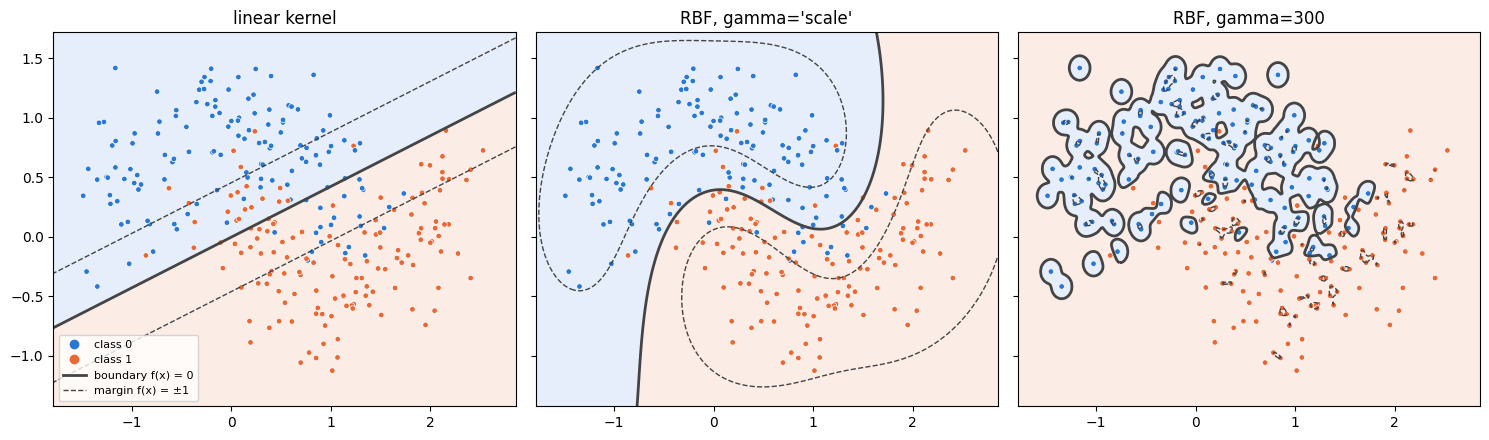

In [4]:
X, y = make_moons(n_samples=400, noise=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

models = {"linear kernel": SVC(kernel="linear"), "RBF, gamma='scale'": SVC(kernel="rbf"),
          "RBF, gamma=300": SVC(kernel="rbf", gamma=300)}
colors = ["#2a78d6", "#eb6834"]
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 300),
                     np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 300))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (name, svm) in zip(axes, models.items()):
    svm.fit(X_train, y_train)
    print(f"{name:20s} train {svm.score(X_train, y_train):.3f}   test {svm.score(X_test, y_test):.3f}   "
          f"support vectors {len(svm.support_)} of {len(X_train)}")
    f = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, f > 0, levels=[-0.5, 0.5, 1.5], cmap=ListedColormap(colors), alpha=0.12)
    ax.contour(xx, yy, f, levels=[-1, 0, 1], colors="#444444", linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
    ax.scatter(X_train[:, 0], X_train[:, 1], c=[colors[label] for label in y_train], s=16, edgecolors="white", linewidths=0.5)
    ax.set_title(name)

axes[0].legend(handles=[Line2D([], [], marker="o", ls="", color=colors[0], label="class 0"),
                        Line2D([], [], marker="o", ls="", color=colors[1], label="class 1"),
                        Line2D([], [], color="#444444", lw=2, label="boundary f(x) = 0"),
                        Line2D([], [], color="#444444", lw=1, ls="--", label="margin f(x) = ±1")], loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

The linear kernel underfits (test 0.808). RBF with the default gamma follows the moon shape (test 0.908).
gamma = 300 draws a small island around single points and predicts one class everywhere else: training accuracy 0.996 but test drops to **0.750**, and 275 of the 280 training points are support vectors.
A support-vector count close to n is a warning sign of overfitting.

# 6. FEATURE SCALING

The RBF kernel compares points by ‖x − z‖², so the feature with the largest range decides the distance.
(A linear SVM is affected too: a small-range feature needs a large weight, and ½‖w‖² penalizes that.)
The breast-cancer features range from below 0.001 to over 4,000.

In [5]:
X, y = load_breast_cancer(return_X_y=True, as_frame=True)
print(X[["fractal dimension error", "mean smoothness", "mean radius", "worst area"]].agg(["min", "max"]).round(4))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
raw = SVC().fit(X_train, y_train)
scaled = make_pipeline(StandardScaler(), SVC()).fit(X_train, y_train)

for name, model in [("without scaling", raw), ("with scaling   ", scaled)]:
    print(f"\n{name}: test accuracy {model.score(X_test, y_test):.3f}, "
          f"errors {np.sum(model.predict(X_test) != y_test)} of {len(y_test)}", end="")

     fractal dimension error  mean smoothness  mean radius  worst area
min                   0.0009           0.0526        6.981       185.2
max                   0.0298           0.1634       28.110      4254.0

without scaling: test accuracy 0.906, errors 16 of 171
with scaling   : test accuracy 0.977, errors 4 of 171

Scaling lifts test accuracy from 0.906 to 0.977 (errors drop from 16 to 4 of 171). Without it, `worst area` (up to 4,254) decides almost every distance.
Standardize with `StandardScaler` (mean 0, standard deviation 1 per feature) inside **one Pipeline**, so the scaler is fit on training data only, including inside cross-validation.

# 7. C VS GAMMA: TUNING THEM TOGETHER

| | C | gamma (RBF) |
|---|---|---|
| Controls | price of a margin violation | how far one point's influence reaches |
| Too small | wide margin, many errors → underfit | boundary close to linear → underfit |
| Too large | narrow margin, chases noise → overfit | islands around single points → overfit |

They interact: a smooth model (small gamma) needs a larger C to fit the data, so the good settings lie on a diagonal of the grid.
Tune them together with cross-validation on a log scale.

In [6]:
grid = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                    {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]}, cv=5).fit(X_train, y_train)

table = pd.DataFrame(grid.cv_results_).pivot_table(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score")
print("Mean CV accuracy (rows = C, columns = gamma):")
print(table.rename_axis(index="C", columns="gamma").round(3))
print(f"\nshare of the majority class: {y_train.mean():.3f}")
print(f"best: {grid.best_params_}, CV accuracy {grid.best_score_:.3f}, test accuracy {grid.score(X_test, y_test):.3f}")

Mean CV accuracy (rows = C, columns = gamma):
gamma  0.001  0.010  0.100  1.000
C                                
0.1    0.703  0.942  0.932  0.628
1.0    0.952  0.972  0.955  0.633
10.0   0.980  0.975  0.952  0.633
100.0  0.977  0.967  0.950  0.633

share of the majority class: 0.628
best: {'svc__C': 10, 'svc__gamma': 0.001}, CV accuracy 0.980, test accuracy 0.971


- **gamma = 1 fails for every C** (0.628 to 0.633, the share of the majority class). In 30 scaled dimensions K(x, z) is almost 0 for any two different points, so a new point resembles no training point and gets the majority class.
- **Small gamma needs a large C**: at gamma = 0.001, C = 0.1 scores 0.703 but C = 10 scores 0.980.
- The best cell is C = 10, gamma = 0.001 (test 0.971). The untuned pipeline in section 6 (C = 1, gamma = "scale" = 1/30 after scaling) scored 0.977, one test point better. Tuning mostly guards against bad settings.

# 8. MULTI-CLASS AND PROBABILITIES

An SVM separates two classes. For K classes, `SVC` trains **one-vs-one**: one SVM per pair of classes, K(K−1)/2 in total, and the class with the most pairwise wins is predicted.
That is more models than **one-vs-rest** (K models, each class against the rest, used by `LinearSVC`), but each sees only two classes' data, which suits kernel training whose cost grows faster than n.

An SVM outputs a score, not a probability. `probability=True` adds **Platt scaling**: a sigmoid fit on the SVM scores, using an internal 5-fold cross-validation (for more than two classes the pairwise probabilities are then combined). As a result:
- training is slower, because of the extra cross-validation fits
- `predict` still uses the scores while `predict_proba` uses the fitted sigmoid, so they can disagree on points near the boundary

The digits data below has 10 classes. All pixels share the range 0–16, so no scaling is needed.

In [7]:
def fit_seconds(model, X, y):
    start = time.perf_counter()
    model.fit(X, y)
    return time.perf_counter() - start


X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

ovo = SVC(decision_function_shape="ovo").fit(X_train, y_train)      # training is one-vs-one either way; "ovo" shows the pairwise scores
print(f"pairwise classifiers: {ovo.decision_function(X_test[:1]).shape[1]}   test accuracy: {ovo.score(X_test, y_test):.3f}")

platt = SVC(probability=True, random_state=0)
t_plain, t_platt = fit_seconds(SVC(), X_train, y_train), fit_seconds(platt, X_train, y_train)
print(f"fit time: {t_plain:.3f} s plain, {t_platt:.3f} s with probability=True ({t_platt / t_plain:.1f}x slower)")

proba_class = platt.classes_[platt.predict_proba(X_test).argmax(axis=1)]
print(f"test points where predict and argmax(predict_proba) disagree: {np.sum(platt.predict(X_test) != proba_class)} of {len(X_test)}")

pairwise classifiers: 45   test accuracy: 0.989
fit time: 0.018 s plain, 0.106 s with probability=True (6.0x slower)


test points where predict and argmax(predict_proba) disagree: 2 of 540


10 classes give 10·9/2 = 45 pairwise SVMs, with test accuracy 0.989. `probability=True` made training 6.0x slower, and on 2 of the 540 test points the most probable class is not the predicted class.

# 9. TRAINING COST ON LARGE DATA

Kernel `SVC` solves a problem defined on the kernel values between all pairs of training points (an n × n matrix), so training time grows roughly between O(n²) and O(n³). It is practical up to tens of thousands of rows.
Prediction costs O(n_SV · d) per point, where n_SV is the number of support vectors and d the number of features (the sum in section 5).

For large data, use a linear SVM: `LinearSVC` or `SGDClassifier(loss="hinge")`, which scale about linearly with n. For a nonlinear boundary on large data, approximate the kernel (`Nystroem`, `RBFSampler`) and train a linear model on the result.

In [8]:
rows = []
for n in [2000, 4000, 8000, 16000]:
    X, y = make_classification(n_samples=n, n_features=20, flip_y=0.05, random_state=0)
    rows.append({"n": n, "SVC (RBF)": fit_seconds(SVC(), X, y), "LinearSVC": fit_seconds(LinearSVC(), X, y),
                 "SGDClassifier (hinge)": fit_seconds(SGDClassifier(loss="hinge", random_state=0), X, y)})
times = pd.DataFrame(rows).set_index("n")
print("fit time in seconds:")
print(times.round(3))
print("\ntime at n = 16,000 / time at n = 2,000:")
print((times.iloc[-1] / times.iloc[0]).round(1).to_string())

fit time in seconds:
       SVC (RBF)  LinearSVC  SGDClassifier (hinge)
n                                                 
2000       0.026      0.002                  0.004
4000       0.147      0.003                  0.012
8000       0.523      0.006                  0.017
16000      1.236      0.012                  0.031

time at n = 16,000 / time at n = 2,000:
SVC (RBF)                48.3
LinearSVC                 6.5
SGDClassifier (hinge)     7.1


8x more data made `SVC` about 48x slower (n² would predict 64x). `LinearSVC` and `SGDClassifier` grew only 6.5x and 7.1x, no faster than n, and stay far below a second.

# 10. WHEN TO USE AN SVM (VS LOGISTIC REGRESSION AND TREES)

**Good for:** small to medium data with a clear margin or a nonlinear boundary (RBF); many features, even more features than rows (linear SVM on text).
**Weak at:** large data with a kernel; problems that need probabilities or an explainable model; heavily overlapping classes, where most points become support vectors and prediction gets slow. It also needs scaling and tuning of C and gamma.

| | Logistic regression | SVM | Decision tree |
|---|---|---|---|
| How it fits | log loss log(1 + e^(−y·f(x))): never zero, every point pulls | hinge loss: zero once y·f(x) ≥ 1, only support vectors matter | threshold splits, one feature at a time |
| Output | probabilities | a score (probabilities need Platt scaling) | class shares in a leaf |
| Nonlinear boundary | add features by hand | kernels | built in (axis-aligned steps) |
| Needs scaling | recommended | yes | no |
| Explainability | coefficients | hard with kernels | readable rules (small trees) |

With a linear boundary, logistic regression and SVM usually reach similar accuracy. Choose logistic regression for probabilities, readable coefficients or a fast baseline on big data; an RBF SVM for small to medium data with a nonlinear boundary; a tree model for unscaled, mixed-type data or readable rules.

**Other SVM models:**
- `SVR` (regression): ε-insensitive loss max(0, |y − f(x)| − ε). Errors inside the ε-tube cost nothing, and the support vectors are the points on or outside the tube. `epsilon` (default 0.1) sets the tube width; C, kernel and gamma work as above.
- `OneClassSVM` (novelty / anomaly detection): learns a boundary around normal data; `nu` is an upper bound on the share of training points treated as outliers.

# 11. KEY PARAMETERS

| Parameter | Default | What it does |
|---|---|---|
| `C` | 1.0 | price of a margin violation; smaller = stronger regularization |
| `kernel` | `"rbf"` | `"linear"`, `"poly"`, `"rbf"`, `"sigmoid"` |
| `gamma` | `"scale"` | reach of each point (rbf / poly / sigmoid); `"scale"` = 1 / (n_features · X.var()) |
| `degree`, `coef0` | 3, 0.0 | polynomial degree; constant term for poly and sigmoid |
| `class_weight` | None | `"balanced"` gives rare classes a larger C (imbalanced data) |
| `probability` | False | Platt-scaled `predict_proba`; slower training |
| `decision_function_shape` | `"ovr"` | shape of the `decision_function` output only; training is always one-vs-one |
| `max_iter` | -1 | solver iteration cap; -1 means no limit |

After fitting: `support_vectors_`, `support_` (their indices), `n_support_` (count per class), `dual_coef_` (αᵢ·yᵢ), `coef_` (w, linear kernel only).
`LinearSVC` uses squared hinge loss by default and also regularizes the intercept, so its results differ slightly from `SVC(kernel="linear")`. `LinearSVC(penalty="l1", dual=False)` gives sparse weights (built-in feature selection).

# 12. INTERVIEW QUESTIONS

### Q1. Explain SVM in 30 seconds.
An SVM finds the boundary with the widest margin between two classes; only the support vectors define it. It minimizes ½‖w‖² + C·Σ hinge loss,
where C trades margin width against violations. Kernels such as RBF give nonlinear boundaries without building new features, and gamma sets
how local the RBF is. Scale the features, tune C and gamma with CV, and use a linear SVM on large data.

### Q2. Why is the margin 2/‖w‖, and why minimize ‖w‖²?
A point's signed distance to the boundary (geometric margin) is y·f(x) / ‖w‖. The margin lines have f(x) = ±1, so each is 1/‖w‖ away and the full width is 2/‖w‖.
Maximizing that equals minimizing ½‖w‖², which is convex, so training finds the global optimum.

### Q3. Hard margin vs soft margin?
Hard margin requires yᵢ·f(xᵢ) ≥ 1 for every point: it fails on overlapping data, and one outlier can drag the boundary. Soft margin adds slack ξᵢ priced by C; as C → ∞ it approaches the hard margin.

### Q4. What are support vectors, and why do only they matter?
The training points with y·f(x) ≤ 1: on the margin, inside it or misclassified. In the dual every other point has αᵢ = 0 and drops out of f(x) = Σ αᵢ yᵢ K(xᵢ, x) + b, so removing it leaves the model unchanged. Smaller C gives more of them.

### Q5. Hinge loss vs log loss?
Hinge max(0, 1 − y·f(x)) is exactly zero beyond the margin, so the solution depends only on the support vectors, but there are no probabilities.
Log loss log(1 + e^(−y·f(x))) is never zero, so every point pulls on the boundary, and the output is a probability.

### Q6. What does C control?
The price of each margin violation (an inverse regularization strength). Small C: wide margin, more violations, underfit risk. Large C: narrow margin, overfit risk.

### Q7. Primal vs dual: why solve the dual?
The primal learns w (one weight per feature); the dual learns αᵢ (one per training point) and uses the data only through dot products. That enables kernels and shows why only support vectors matter.
The primal is cheaper when rows far outnumber features (`LinearSVC(dual=False)`); kernel `SVC` solves the dual.

### Q8. What is the kernel trick, and what makes a valid kernel?
Replace x·z with K(x, z) = φ(x)·φ(z) to fit a linear boundary in a high-dimensional (for RBF, infinite) feature space without computing φ(x).
By Mercer's condition, K must produce symmetric positive semi-definite kernel matrices; that keeps the problem convex.

### Q9. What is the RBF kernel, and what does gamma do?
exp(−γ‖x − z‖²) is a similarity: 1 for identical points, near 0 far apart. Gamma sets how far a point's influence reaches: small = smooth, almost linear; large = islands around single points and overfitting.

### Q10. How would you train and tune an SVM in practice?
Put `StandardScaler` and `SVC` in one Pipeline; start with RBF (linear for text, many features or large data). Grid-search C and gamma together on a log scale with CV, and use `class_weight="balanced"` for imbalanced classes. A support-vector count close to n signals overfitting.

### Q11. Why scale features for an SVM?
RBF uses distances and ½‖w‖² penalizes all weights equally, so the largest-range feature dominates. On breast cancer, scaling took accuracy from 0.906 to 0.977.

### Q12. How does SVC handle multi-class and probabilities?
One-vs-one: K(K−1)/2 binary SVMs and a vote (`LinearSVC` uses one-vs-rest). `probability=True` adds Platt scaling with internal 5-fold CV: slower, and `predict_proba` can disagree with `predict`.
`LinearSVC` has no `predict_proba`; wrap it in `CalibratedClassifierCV`.

### Q13. How does SVR work?
It fits f(x) inside an ε-tube: errors smaller than ε cost nothing (ε-insensitive loss max(0, |y − f(x)| − ε)), and only points on or outside the tube become support vectors. C, epsilon, kernel and gamma play the same roles as in classification.

### Q14. What is the complexity, and what would you use on 10 million rows?
Kernel SVC trains in roughly O(n²) to O(n³) and predicts in O(n_SV · d) per point. On 10 million rows use `LinearSVC`, `SGDClassifier(loss="hinge")` or logistic regression, plus `Nystroem` if the boundary must be nonlinear.

### Q15. SVM vs logistic regression vs trees: when would you not use an SVM?
With a linear boundary, SVM and logistic regression score about the same; logistic regression adds probabilities and readable coefficients.
Skip a kernel SVM on very large data, when you need calibrated probabilities or explanations, or on mixed-type tabular data, where tree models (e.g. gradient boosting) need no scaling and are often stronger.

# 13. IN MY OWN WORDS

Write this from memory, without looking above:

- What an SVM does:
- What the support vectors are, and why only they matter:
- How the kernel trick works:
- What C and gamma control:
- When I would not use a kernel SVM:

# 14. APPENDIX: LINEAR SVM FROM SCRATCH

Stochastic sub-gradient descent on the primal, one sample at a time: a safe point (y·f(x) ≥ 1) only shrinks w; a violator also pulls w and b toward classifying it correctly.
(scikit-learn's `SVC` instead solves the dual with libsvm's SMO-type solver.)

**Note on C.** The shrink step runs for every sample, so one pass applies the regularization n times but each hinge term once.
That minimizes n·½‖w‖² + C·Σ hinge, which has the same solution as ½‖w‖² + (C/n)·Σ hinge. So this model's C equals sklearn's C/n: its C = 1 matches `SVC(kernel="linear", C=1/n)`, not `C=1`.

In [9]:
def fit_linear_svm(X, y, C=1.0, lr=0.001, epochs=1000):
    # y must be −1 / +1
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(epochs):
        for xi, yi in zip(X, y):
            if yi * (xi @ w + b) >= 1:
                w -= lr * w                        # safe point: regularization gradient only
            else:
                w -= lr * (w - C * yi * xi)        # violator: regularization + hinge gradient
                b += lr * C * yi
    return w, b


X, y = make_blobs(n_samples=100, centers=2, cluster_std=1.5, random_state=0)
y = np.where(y == 1, 1, -1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
n = len(X_train)

w, b = fit_linear_svm(X_train, y_train, C=1.0)
print(f"scratch, C = 1           w = {np.round(w, 3)}, b = {b:.3f}")
for C in (1.0, 1.0 / n):
    svm = SVC(kernel="linear", C=C).fit(X_train, y_train)
    print(f"SVC, C = {C:<6.4g}           w = {np.round(svm.coef_.ravel(), 3)}, b = {svm.intercept_[0]:.3f}")

scratch, C = 1           w = [ 0.177 -0.407], b = 0.792
SVC, C = 1                w = [ 0.19  -0.844], b = 1.885
SVC, C = 0.0125           w = [ 0.177 -0.412], b = 0.793


With n = 80, the scratch model (C = 1) lands on almost the same w and b as `SVC` with C = 1/80 = 0.0125, and far from `SVC` with C = 1.